# Moleküldynamik in zwei Dimensionen
## Eine kleine, veränderbare MD-Engine mit NumPy
**Ziel:** Newtons Bewegungsgleichungen integrieren, Temperatur und Druck regeln und eine Trajektorie untersuchen. Alle Teilchen sind identisch und wechselwirken über ein Lennard-Jones-Potential. Keine Bindungen, keine Elektrostatik.

**Start:** In Jupyter „Run All“ ausführen. Benötigt werden **NumPy und Matplotlib**, zusätzlich die mit Jupyter gelieferte `IPython.display`-Schnittstelle für den Player. Kein SciPy, MD-Paket, Widget oder FFmpeg erforderlich. Alle Funktionen stehen in diesem Notebook.

```text
Parameter → Positionen + Geschwindigkeiten → Anfangskräfte
                                             ↓
                 ┌── halber Geschwindigkeitsschritt
                 │   Positionen bewegen + periodisch falten
                 │   neue Kräfte → zweiter halber Geschwindigkeitsschritt
                 │   Berendsen-Thermostat (optional)
                 │   Berendsen-Barostat (optional) → Kräfte aktualisieren
                 │   Observablen / ausgewählte Bilder speichern
                 └── nächster Zeitschritt
                                             ↓
                            NumPy-Arrays → Diagramme + Animation
```

Wir verwenden reduzierte Einheiten: $m=\sigma=\epsilon=k_B=1$. Länge: $\sigma$, Energie und Temperatur: $\epsilon$ bzw. $\epsilon/k_B$, Zeit: $\sigma\sqrt{m/\epsilon}$, Druck in 2D: $\epsilon/\sigma^2$. Das „Volumen“ ist hier die **Fläche** $V=L^2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from time import perf_counter

Matplotlib is building the font cache; this may take a moment.


### 1. Das Modell und seine Grenzen
Die quadratische Box hat periodische Ränder. Für jedes Paar verwenden wir den kürzesten Abstandsvektor („minimum image“): $\mathbf r_{ij}\leftarrow\mathbf r_{ij}-L\,\mathrm{round}(\mathbf r_{ij}/L)$.

$$u(r)=4(r^{-12}-r^{-6}),\qquad
\mathbf F_{ij}=24(2r^{-12}-r^{-6})\frac{\mathbf r_{ij}}{r^2}.$$

Bei $r_c=2.5$ schneiden wir ab und verschieben das Potential um $u(r_c)$: $u_\mathrm{cut}(r)=u(r)-u(r_c)$ für $r<r_c$, sonst null. Das Potential ist stetig, die Kraft am Cutoff nicht; deshalb ist die Energieerhaltung nicht perfekt. Es gibt keine Fernbereichskorrektur. Immer muss $r_c<L/2$ gelten.

Die Kraftfunktion berechnet alle Paare mit NumPy-Broadcasting, ohne Python-Schleife über Teilchen. Rechenzeit und temporärer Speicher wachsen mit $N^2$: übersichtlich und schnell für etwa 64–144 Teilchen, nicht für große Systeme. Jedes Paar steht zweimal in der Matrix, deshalb erhalten Energie und Virial einen Faktor $1/2$.

In [2]:
def forces(r, L, rc=2.5):
    """Positionen (N, 2) → Kräfte (N, 2), potentielle Energie, Paarvirial."""
    if not np.isfinite(L) or L <= 2 * rc:
        raise ValueError("Minimum image verlangt L > 2 * rc. Parameter ändern.")
    dr = r[:, None, :] - r[None, :, :]       # dr[i,j] = r_i - r_j
    dr -= L * np.rint(dr / L)
    r2 = np.sum(dr * dr, axis=2)
    np.fill_diagonal(r2, np.inf)            # keine Selbstwechselwirkung
    if np.any(r2 < 1e-12):
        raise ValueError("Teilchen überlappen; Initialisierung / dt prüfen.")
    inv_r2 = np.where(r2 < rc**2, 1.0 / r2, 0.0)
    inv_r6 = inv_r2**3
    factor = 24 * inv_r2 * inv_r6 * (2 * inv_r6 - 1)
    pair_force = factor[:, :, None] * dr
    F = pair_force.sum(axis=1)
    u_cut = 4 * (rc**-12 - rc**-6)
    U = 0.5 * np.sum(np.where(r2 < rc**2,
                              4 * inv_r6 * (inv_r6 - 1) - u_cut, 0.0))
    W = 0.5 * np.sum(dr * pair_force)        # Summe i<j: r_ij · F_ij
    return F, U, W


def initialize(n_side=8, density=0.65, T0=1.0, seed=7):
    """Quadratisches Gitter; Zufallsgeschwindigkeiten ohne Schwerpunktsdrift."""
    if n_side < 2 or density <= 0 or T0 <= 0:
        raise ValueError("n_side >= 2, density > 0 und T0 > 0 erforderlich.")
    N = n_side**2
    L = np.sqrt(N / density)
    grid = (np.arange(n_side) + 0.5) * L / n_side
    r = np.stack(np.meshgrid(grid, grid), axis=-1).reshape(N, 2)
    v = np.random.default_rng(seed).normal(size=(N, 2))
    v -= v.mean(axis=0)                     # zwei COM-Freiheitsgrade entfernen
    dof = 2 * N - 2
    v *= np.sqrt(dof * T0 / np.sum(v * v))
    return r, v, L


def observables(v, L, W):
    """Kinetische Energie, Temperatur und mechanischer Virialdruck in 2D."""
    K = 0.5 * np.sum(v * v)
    T = 2 * K / (2 * len(v) - 2)
    P = (2 * K + W) / (2 * L**2)
    return K, T, P

### 2. Temperatur und Druck: Wo steckt die Dimension?
Bei entferntem Schwerpunktimpuls sind $f=2N-2$ Freiheitsgrade aktiv:
$$K=\tfrac12\sum_i |\mathbf v_i|^2,\quad T=2K/f,\quad
P=\frac{2K+\sum_{i<j}\mathbf r_{ij}\cdot\mathbf F_{ij}}{2V}.$$
Wir benutzen im Druck ausdrücklich $2K$, nicht $2NT$: Bei endlichem $N$ und entferntem Schwerpunkt unterscheiden sich diese Ausdrücke.

**Berendsen-Thermostat:** Nach dem Verlet-Schritt skalieren wir alle Geschwindigkeiten mit
$$\lambda=\sqrt{1+\frac{\Delta t}{\tau_T}\left(\frac{T_0}{T}-1\right)}.$$
Die Dimension steckt in der Berechnung von $T$; im Skalierungsfaktor gibt es keinen zusätzlichen Faktor 2.

**Isotroper Berendsen-Barostat in 2D:** Aus $\dot V/V=\kappa_T(P-P_0)/\tau_P$ folgt mit einem expliziten Flächenschritt
$$a=1+\frac{\kappa_T\Delta t}{\tau_P}(P-P_0),\qquad
\mu=\sqrt{a},\qquad L\leftarrow\mu L,\quad\mathbf r_i\leftarrow\mu\mathbf r_i.$$
Hoher Innendruck vergrößert die Box. Die **Quadratwurzel** ersetzt die dritte Wurzel aus 3D; bis zur ersten Ordnung ist $\mu\approx1+\kappa_T\Delta t(P-P_0)/(2\tau_P)$. $\kappa_T$ ist eine geschätzte **2D-Flächenkompressibilität**, in inversen Druckeinheiten, kein Wasserwert aus 3D. Hier ist sie ein einstellbarer Kopplungsparameter. Geschwindigkeiten werden durch diesen Barostat nicht skaliert. Nach der Boxänderung berechnen wir Kräfte und Virial erneut.

Dies ist eine einfache sequenzielle Kopplung an Velocity-Verlet. Sie ist mit aktiven Reglern nicht energieerhaltend oder zeitumkehrbar. Berendsen unterdrückt Fluktuationen und erzeugt **kein korrektes NVT-/NPT-Ensemble**. Die Daten eignen sich zum Lernen und zur qualitativen Analyse, nicht für exakte Fluktuationsformeln.

Quelle für die Weak-Coupling-Verfahren: [GROMACS, Molecular Dynamics](https://manual.gromacs.org/documentation/2026.0/reference-manual/algorithms/molecular-dynamics.html), Abschnitte „Berendsen temperature coupling“ und „Berendsen pressure coupling“. Die Flächenform und Freiheitsgrade oben sind die hier explizit hergeleitete 2D-Anpassung.

In [3]:
def simulate(n_side=8, density=0.65, T0=1.0, P0=1.0,
             dt=0.003, steps=12000, tau_T=0.3, tau_P=3.0,
             compressibility=0.5, thermostat=True, barostat=True,
             sample_every=10, frame_every=40, rc=2.5, seed=7):
    """Einfache MD. Messwerte und Frames haben getrennte Zeitachsen.

    Beide Regler aus: NVE; nur Thermostat an: feste Fläche;
    beide an: Berendsen-Kopplung für Temperatur und Druck.
    Jeder Aufruf startet neu, mit reproduzierbarer Initialisierung.
    """
    if dt <= 0 or steps < 1 or sample_every < 1 or frame_every < 1 or rc <= 0:
        raise ValueError("dt, steps, Speicherintervalle und rc müssen positiv sein.")
    if tau_T <= 0 or tau_P <= 0 or compressibility <= 0:
        raise ValueError("Kopplungszeiten und Kompressibilität müssen positiv sein.")
    r, v, L = initialize(n_side, density, T0, seed)
    F, U, W = forces(r, L, rc)
    # Vorab reservieren: keine ständig wachsenden Arrays in der Schleife.
    data = {key: np.empty(steps // sample_every + 1)
            for key in ("time", "temperature", "pressure", "volume",
                        "kinetic_energy", "potential_energy")}
    trajectory = np.empty((steps // frame_every + 1, len(r), 2))
    box_length = np.empty(len(trajectory))
    frame_time = np.empty(len(trajectory))

    for step in range(steps + 1):
        if step > 0:
            # Velocity-Verlet: kick – drift – Kraft – kick (m = 1).
            v += 0.5 * dt * F
            r = (r + dt * v) % L
            F, U, W = forces(r, L, rc)
            v += 0.5 * dt * F

            if thermostat:
                _, T, _ = observables(v, L, W)
                if not np.isfinite(T) or T <= 0:
                    raise ValueError("Ungültige Temperatur; dt / Startzustand prüfen.")
                lambda2 = 1 + dt / tau_T * (T0 / T - 1)
                if lambda2 <= 0:
                    raise ValueError("Thermostat zu stark: dt reduzieren / tau_T erhöhen.")
                v *= np.sqrt(lambda2)

            if barostat:
                _, _, P = observables(v, L, W)
                area_factor = 1 + compressibility * dt / tau_P * (P - P0)
                # Abbrechen statt instabile Skalierung unbemerkt abzuschneiden.
                if not np.isfinite(area_factor) or abs(area_factor - 1) > 0.05:
                    raise ValueError("Barostat zu stark: dt senken / tau_P erhöhen.")
                mu = np.sqrt(area_factor)
                r *= mu
                L *= mu
                F, U, W = forces(r, L, rc)

        if step % sample_every == 0:
            k = step // sample_every
            K, T, P = observables(v, L, W)
            values = (step * dt, T, P, L**2, K, U)
            if not np.all(np.isfinite(values)):
                raise ValueError("Simulation instabil: dt und Anfangsdichte prüfen.")
            for key, value in zip(data, values):
                data[key][k] = value
        if step % frame_every == 0:
            k = step // frame_every
            trajectory[k], box_length[k], frame_time[k] = r, L, step * dt

    data.update(trajectory=trajectory, box_length=box_length, frame_time=frame_time,
                total_energy=data["kinetic_energy"] + data["potential_energy"],
                final_positions=r.copy(), final_velocities=v.copy(), final_L=L)
    return data

### 3. Simulation starten
64 Teilchen und 12 000 Schritte sind ein kurzer Lehrlauf, keine Garantie für konvergierte Mittelwerte. `steps` erhöhen, um länger zu messen; `sample_every` und `frame_every` steuern unabhängig die Datenmenge. Die volle Trajektorie wird nicht für jeden Integrationsschritt gespeichert. Auf größeren Systemen dominiert die quadratische Kraftberechnung; der Barostat benötigt eine zusätzliche Kraftauswertung pro Schritt.

Ändere zunächst nur einen Parameter. Sehr kleine Kopplungszeiten, große Zeitschritte oder eine zu hohe Startdichte können den Lauf destabilisieren. Bei Änderungen anschließend diese und alle folgenden Zellen neu ausführen.

In [4]:
parameters = dict(n_side=8, density=0.65, T0=1.0, P0=1.0,
                  dt=0.003, steps=12000, tau_T=0.3, tau_P=3.0,
                  compressibility=0.5, thermostat=True, barostat=True,
                  sample_every=10, frame_every=40, seed=7)
start = perf_counter()
result = simulate(**parameters)
elapsed = perf_counter() - start
print(f"{parameters['steps']:,} Schritte in {elapsed:.2f} s "
      f"({parameters['steps'] / elapsed:.0f} Schritte/s)")

# Direkte NumPy-Arrays für studentische Analysen:
time = result["time"]
temperature = result["temperature"]
pressure = result["pressure"]
volume = result["volume"]                  # Fläche in 2D!
energy = result["total_energy"]
trajectory = result["trajectory"]         # (n_frames, N, 2), periodisch gefaltet
box_length = result["box_length"]         # (n_frames,)
frame_time = result["frame_time"]
print("Messwerte:", time.shape, "| Trajektorie:", trajectory.shape)

12,000 Schritte in 9.61 s (1248 Schritte/s)
Messwerte: (1201,) | Trajektorie: (301, 64, 2)


### 4. Erst anschauen, dann analysieren
Messwerte stammen jeweils aus demselben Zustand **nach** beiden Kopplungsschritten; Index 0 ist der Initialzustand. Die gestrichelte Linie markiert einen zunächst willkürlich gewählten Äquilibrierungsabschnitt von 30 %. Prüfe selbst, ob das ausreicht. Energie muss bei aktiver Temperatur-/Druckkopplung nicht konstant sein.

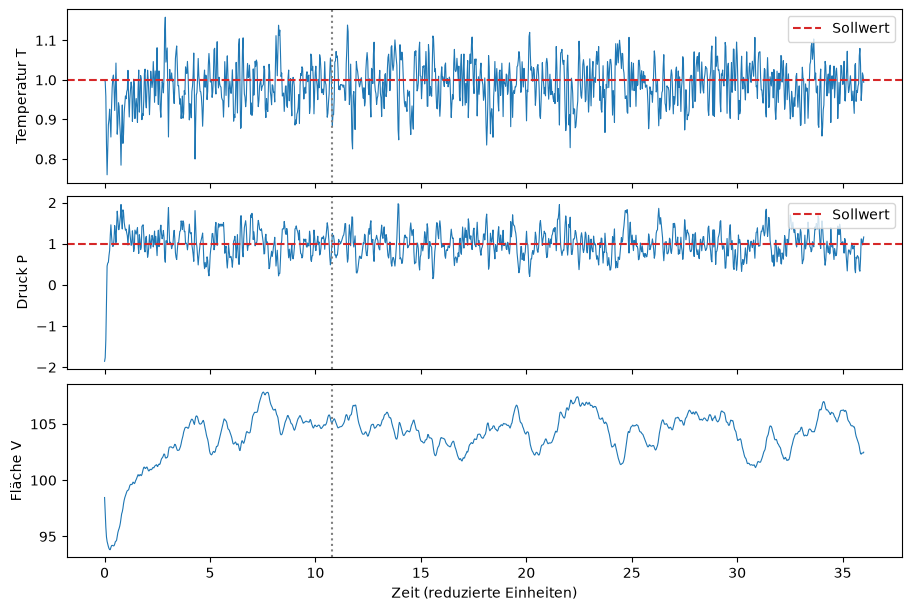

In [5]:
equilibration_time = 0.30 * time[-1]
production = time >= equilibration_time
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
for ax, y, label, target in zip(axes, [temperature, pressure, volume],
                              ["Temperatur T", "Druck P", "Fläche V"],
                              [parameters["T0"], parameters["P0"], None]):
    ax.plot(time, y, lw=0.8)
    ax.axvline(equilibration_time, color="gray", ls=":")
    if target is not None:
        ax.axhline(target, color="tab:red", ls="--", label="Sollwert")
        ax.legend(loc="upper right")
    ax.set_ylabel(label)
axes[-1].set_xlabel("Zeit (reduzierte Einheiten)")
plt.show()

### 5. Trajektorie direkt abspielen
Der HTML-Player bietet Play/Pause und einen Schieberegler. Die schwarze Umrandung zeigt die tatsächliche Boxgröße; die Achsenskalierung bleibt fest, damit Flächenänderungen sichtbar sind. Teilchen springen an periodischen Rändern auf die andere Seite. Die Markierungsgröße ist schematisch.

Für eine kompakte Notebook-Datei zeigt der Player höchstens 160 gespeicherte Bilder, gleichmäßig über den Lauf verteilt. `trajectory` enthält weiterhin **alle** gespeicherten Bilder. Die Darstellung nutzt eingebettete Bilder und JavaScript, keinen Videocodec. Bei blockiertem HTML das selbst erzeugte Notebook in Jupyter als vertrauenswürdig markieren und die Zelle erneut ausführen.

In [6]:
frame_indices = np.unique(np.linspace(0, len(trajectory) - 1,
                                      min(160, len(trajectory)), dtype=int))
fig, ax = plt.subplots(figsize=(5, 5))
limit = box_length.max() * 1.04
ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="x / σ", ylabel="y / σ")
ax.set_aspect("equal")
particles = ax.scatter([], [], s=30, color="tab:blue")
box, = ax.plot([], [], color="black", lw=1)
title = ax.set_title("")

def update(frame):
    L = box_length[frame]
    particles.set_offsets(trajectory[frame])
    box.set_data([0, L, L, 0, 0], [0, 0, L, L, 0])
    title.set_text(f"t = {frame_time[frame]:.2f} | V = {L**2:.2f}")
    return particles, box, title

animation = FuncAnimation(fig, update, frames=frame_indices, interval=60, blit=False)
player = animation.to_jshtml()
plt.close(fig)                              # kein zusätzliches Standbild
display(HTML(player))

### 6. Eigene Analysen
Die Arrays `time`, `temperature`, `pressure`, `volume` und `energy` haben dieselbe Länge. `trajectory`, `box_length` und `frame_time` besitzen eine eigene, gröbere Zeitachse. Alle Daten sind in reduzierten Einheiten.

1. Zeichne `pressure[production]` gegen `volume[production]`. Was unterscheidet diese fluktuierende Punktwolke von einer thermodynamischen Isotherme?
2. Für eine Isotherme: Simuliere mehrere **feste Flächen** (`barostat=False`, verschiedene `density`), äquilibriere jeden Lauf und bestimme mittleren Druck und Fläche bei gleicher Temperatur.
3. Schalte beide Regler aus und untersuche die Energieerhaltung für verschiedene `dt`. Wie wirken sich Cutoff und Schrittweite aus?
4. Variiere `tau_T` und `tau_P`. Wie ändern sich Relaxationszeit und Fluktuationen? Fluktuationsformeln für Kompressibilität sind mit Berendsen nicht zuverlässig.
5. Bestimme Autokorrelationen und Blockmittelwerte: Aufeinanderfolgende Messwerte sind nicht unabhängig. Längere Läufe und mehrere Seeds helfen bei Unsicherheiten.
6. Fortgeschritten: Implementiere eine Nachbarliste oder ein am Cutoff geglättetes Potential. Für Diffusion brauchst du ungefaltete Koordinaten; gespeicherte periodische Positionen allein dürfen nicht direkt differenziert werden, und eine veränderliche Box erfordert zusätzliche Sorgfalt.

Die folgende Zelle ist bewusst offen für eure Auswertung:

In [7]:
# Beispielzugriff – hier die eigene Analyse ergänzen.
print(f"Mittlere Temperatur nach dem gewählten Einschwingen: {temperature[production].mean():.3f}")

# Optional: sämtliche Arrays speichern (bei Bedarf einkommentieren).
# np.savez_compressed("md_2d_daten.npz", **result)
# geladen = np.load("md_2d_daten.npz")

Mittlere Temperatur nach dem gewählten Einschwingen: 0.991
